# Kikuchi COM vs disk-pair intensity — combined figure

Companion to `create_paper_figs_kikuchi_short_range.ipynb` and
`create_paper_figs_disks_intensity_MORE_DISKS.ipynb`; same metrics, styling and conventions.

**Fixed relative to the previous version**

- **Kikuchi metric.** Read from `cache_shortrange/` (written by the short-range notebook): the
  masked union-centroid COM from `kikuchi_com.py`, full box, exact mirror. The old cell took the
  midpoint of the two top-third boxes' separate centroids with the off-by-one mirror.
- **Kikuchi datasets.** PTO is the 21 September re-run. The old `PTO_kikuchi_15_slice_...` file is
  not PbTiO$_3$ (its zone-axis ratio is BaTiO$_3$'s).
- **Disk metric.** Normalised `(b1-b2)/(b1+b2) x 100`, exact mirror. The old code plotted raw
  summed counts labelled "%".
- **Units.** Kikuchi in $\mathrm{\AA}^{-1}$, disks in %, per-material calibration from the supercell.
- **Polarisation alignment** is one flag, `y(t) -> -y(-t)`, applied to *both* methods of a
  material, so a panel never compares a flipped curve with an unflipped one. See the config cell.
- **No spline smoothing.** The tilt-to-tilt structure is deterministic, not noise; a spline
  through it invents curve between the samples.
- The per-material diagnostic figure is dropped; it is now the disks notebook's figure.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.style.use("paper")   # ~/.config/matplotlib/stylelib

sys.path.insert(0, "..")
from kikuchi_com import mirror_box, BORACITE_EXTENT, DISK_LATTICE, disk_row_box   # exact half-open reflection about n/2
from polarisation_direction import P_REVERSED

TILT_SIGN = -1     # x-axis convention, applied to the tilt axis only
CYCLE = plt.rcParams["axes.prop_cycle"].by_key()["color"]
C_KIK, C_DISK = CYCLE[0], CYCLE[1]              # navy, orange
FG, ZERO = "black", "black"
MM = 1 / 25.4

# flip_polar: y_aligned(t) = -y(-t), the exact effect of mirroring the structure
# through the plane perpendicular to P. Applied identically to both methods.
#   BTO:      CIF polarised opposite to PTO (-38.2 vs +17.9 uC/cm2 nominal) -> flipped.
#   boracite: CIF polarisation direction not established -> left as simulated.
#             (The disks figure flips it to match PTO at low angle; the Kikuchi figure
#             does not. Here one convention per material is needed, and "as simulated"
#             is the only one that is not a choice.)
# disk_box: the single disk-pair ROI shown, (label, label, (order, n_disks)); box1 is
# built by kikuchi_com.disk_row_box on the detected disk lattice.
# Disk data: the 4096-grid, full-detector Kikuchi short-range sims (41 tilts, +-0.6 deg). The
# dedicated disk sims (data/*_disks.npz) used a 1024 grid, which is not converged: boracite
# {100} 1x1 at zero tilt is -88.7 % at 1024 and -68.8 % at 4096 (these sims give -68.6 %).
MATERIALS = {
    "PTO": dict(
        formula=r"PbTiO$_3$", abbr="PTO", disk_path="../data/short_range/PTO_short_range_21_sept_asymmetry_data.npz",
        cell=(3.9423, 3.8862), nrep=30, flip_polar=False,
        disk_box=("001", r"1$\times$3", (1, 3))),
    "BTO": dict(
        formula=r"BaTiO$_3$", abbr="BTO", disk_path="../data/short_range/BTO_kikuchi_final_15_slice_asymmetry_data.npz",
        cell=(4.0230, 3.9905), nrep=30, flip_polar=True,
        disk_box=("001", r"1$\times$3", (1, 3))),
    "Boracite": dict(
        formula=r"Cu$_3$B$_7$ClO$_{13}$", abbr="boracite", disk_path="../data/short_range/1_slice_thickness/boracite_kikuchi_1_slice_asymmetry_data.npz",
        cell=(17.1032, 17.1032), nrep=7, flip_polar=False,
        extent=(BORACITE_EXTENT, BORACITE_EXTENT),   # abTEM box, see kikuchi_com
        disk_box=("002", r"1$\times$1", (1, 1))),
}
for cfg in MATERIALS.values():
    a0, a1 = cfg["cell"]; n = cfg["nrep"]
    e0, e1 = cfg.get("extent", (n*a0, n*a1))       # simulation box (A)
    cfg["kpp"] = (1.0 / e0, 1.0 / e1)               # inverse angstrom per pixel

In [2]:
def asym(patterns, box1, box2):
    """Normalised intensity asymmetry, per cent: (b1 - b2) / (b1 + b2)."""
    (y1, y2), (x1, x2) = box1
    (Y1, Y2), (X1, X2) = box2
    b1 = patterns[:, y1:y2, x1:x2].sum(axis=(1, 2))
    b2 = patterns[:, Y1:Y2, X1:X2].sum(axis=(1, 2))
    return (b1 - b2) / (b1 + b2) * 100


def load_disk(name, cfg):
    d = np.load(cfg["disk_path"])
    p = d["diffraction_images"].astype(np.float64)
    if p.ndim == 4:
        p = p[:, 0]
    H, W = p.shape[1:]
    (lo, hi), (x0, x1) = box1 = disk_row_box((H, W), *DISK_LATTICE[name], *cfg["disk_box"][2])
    a, b, _, _ = mirror_box((lo, hi, x0, x1), H)
    return np.asarray(d["tilt_y_values"], dtype=float), asym(p, box1, ((a, b), (x0, x1)))


def load_kikuchi(name):
    """Corrected masked COM (px, polar axis), cached by the short-range notebook."""
    d = np.load(f"cache_shortrange/{name}.npz")
    # positive = top (low row index) brighter, as for the disk pair; masked_com is
    # + towards higher index, so it is negated
    return d["tilt"], -d["com"]


# y_aligned(t) = -y(-t): both tilt grids are symmetric and ascending, so this is a
# reversal plus a negation

raw_data = {}
for name, cfg in MATERIALS.items():
    td, disk = load_disk(name, cfg)
    tk, com = load_kikuchi(name)
    assert np.allclose(td, -td[::-1]) and np.allclose(tk, -tk[::-1])
    raw_data[name] = dict(td=td, disk=disk, tk=tk, com=com)


def build(mode="paper"):
    """paper: flip_polar per MATERIALS. raw: no polar alignment, tilt as simulated
    (TILT_SIGN = +1). aligned: every material mirrored to PTO's polarisation (P_REVERSED)."""
    out = {}
    for name, cfg in MATERIALS.items():
        d = raw_data[name]
        rev = {"paper": cfg["flip_polar"], "raw": False, "aligned": P_REVERSED[name],
               "final": not P_REVERSED[name]}[mode]   # final: P towards the top box
        f = (lambda v: -v[::-1]) if rev else (lambda v: v)
        ts = 1 if mode == "raw" else TILT_SIGN
        out[name] = dict(t_disk=ts*d["td"], disk=f(d["disk"]),
                         t_kik=ts*d["tk"], kik=f(d["com"])*cfg["kpp"][0])
    return out


RESULTS = {m: build(m) for m in ("paper", "raw", "aligned", "final")}
for name, r in RESULTS["paper"].items():
    print(f"{name:9s} disk n={len(r['disk'])} {r['disk'].min():+7.3f}..{r['disk'].max():+7.3f} %   "
          f"Kikuchi n={len(r['kik'])} {r['kik'].min():+7.4f}..{r['kik'].max():+7.4f} A^-1")

PTO       disk n=41 -36.672..+69.584 %   Kikuchi n=41 -0.5440..+0.8911 A^-1
BTO       disk n=41 -78.449..+74.795 %   Kikuchi n=41 -0.8660..+0.8186 A^-1
Boracite  disk n=41 -97.179..+68.719 %   Kikuchi n=41 -0.5529..+0.6454 A^-1


## Combined figure — Kikuchi COM (left axis) vs disk-pair asymmetry (right axis)

Shown over the disk tilt range (±0.25°); the Kikuchi sweep extends to ±0.6°. Each axis is
shared across columns and symmetric about zero.

saved figures/combined_disk_kikuchi.{pdf,png}


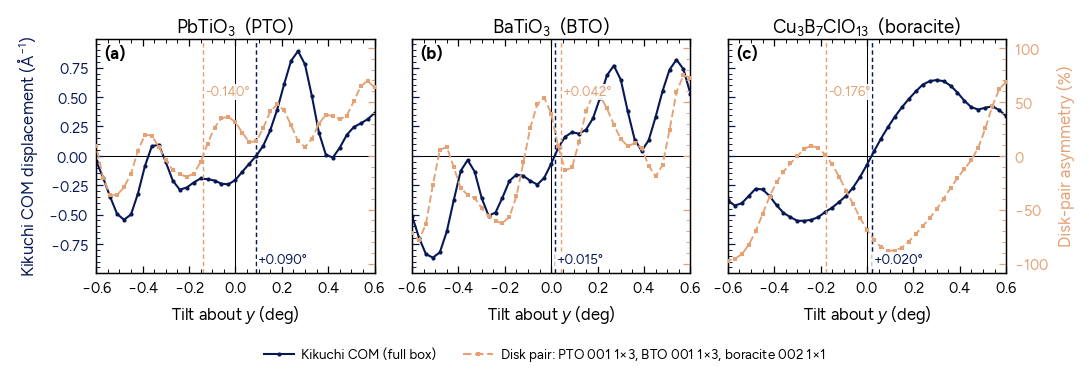

In [3]:
def panel_label(ax, txt, colour=FG):
    ax.text(0.03, 0.965, f"({txt})", transform=ax.transAxes, va="top", ha="left",
            fontsize=8, fontweight="bold", color=colour)


def in_range(t, y, lim):
    return y[np.abs(t) <= lim + 1e-9]


def zero_crossing(t, y, lim):
    """Tilt of the sign change nearest zero tilt within +-lim, linearly interpolated."""
    i = np.flatnonzero(np.sign(y[:-1]) * np.sign(y[1:]) < 0)
    tc = t[i] - y[i] * (t[i+1] - t[i]) / (y[i+1] - y[i])
    tc = tc[np.abs(tc) <= lim]
    return tc[np.argmin(np.abs(tc))] if len(tc) else None


def mark_crossings(ax, r):
    """Dashed vertical line + angle at each method's sign change nearest zero tilt.
    Kikuchi label along the bottom, disk label along the top, each in its curve's colour."""
    for t, y, colour, ypos, va in ((r["t_kik"], r["kik"], C_KIK, 0.03, "bottom"),
                                   (r["t_disk"], r["disk"], C_DISK, 0.80, "top")):
        tc = zero_crossing(t, y, t_lim)
        if tc is None:
            continue
        ax.axvline(tc, color=colour, lw=0.7, ls=(0, (3, 2)), zorder=1)
        ax.text(tc + (0.008 if tc < 0.15 else -0.008), ypos, f"{tc:+.3f}°",
                transform=ax.get_xaxis_transform(), ha="left" if tc < 0.15 else "right",
                va=va, fontsize=6.5, color=colour, zorder=6,
                bbox=dict(fc="white", ec="none", pad=0.6, alpha=0.9))


handles = [Line2D([], [], color=C_KIK, marker="o", ms=2.0, mew=0),
           Line2D([], [], color=C_DISK, marker="s", ms=1.8, mew=0, ls=(0, (4, 1.8)))]
labels = ["Kikuchi COM (full box)",
          "Disk pair: " + ", ".join(f"{c['abbr']} {c['disk_box'][0]} {c['disk_box'][1]}"
                                    for c in MATERIALS.values())]
t_lim = max(np.abs(r["t_disk"]).max() for r in RESULTS["paper"].values())


def combined_figure(mode="paper"):
    """Twin axes. mode: "paper", "raw" ('unflipped_' prefix) or "aligned" ('aligned_' prefix)."""
    results, pre = RESULTS[mode], {"paper": "", "raw": "unflipped_", "aligned": "aligned_",
                              "final": "corrected_final/corrected_final_"}[mode]
    k_lim = max(np.abs(in_range(r["t_kik"], r["kik"], t_lim)).max() for r in results.values()) * 1.12
    d_lim = max(np.abs(r["disk"]).max() for r in results.values()) * 1.12

    fig, axes = plt.subplots(1, 3, figsize=(180*MM, 58*MM), layout="constrained")
    fig.get_layout_engine().set(h_pad=0.01, w_pad=0.01, wspace=0.03)
    letters = iter("abc")

    for col, (name, cfg) in enumerate(MATERIALS.items()):
        r = results[name]
        ax = axes[col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        ax.plot(r["t_kik"], r["kik"], "-o", ms=2.0, color=C_KIK, markeredgewidth=0, zorder=3)
        ax.set_xlim(-t_lim, t_lim); ax.set_ylim(-k_lim, k_lim)
        ax.tick_params(axis="y", right=False, which="both", colors=C_KIK)
        ax.set_xlabel(r"Tilt about $y$ (deg)")
        if col == 0:
            ax.set_ylabel(r"Kikuchi COM displacement ($\mathrm{\AA}^{-1}$)", color=C_KIK)
        else:
            ax.set_yticklabels([])

        ax2 = ax.twinx()
        ax2.plot(r["t_disk"], r["disk"], marker="s", ms=1.8, lw=0.9, ls=(0, (4, 1.8)),
                 color=C_DISK, markeredgewidth=0, zorder=3)
        ax2.set_ylim(-d_lim, d_lim)
        mark_crossings(ax2, r)          # on the twin so labels sit above both curves
        ax2.tick_params(axis="y", left=False, which="both", colors=C_DISK)
        if col == 2:
            ax2.set_ylabel("Disk-pair asymmetry (%)", color=C_DISK)
        else:
            ax2.set_yticklabels([])

        ax.set_title(rf"{cfg['formula']}  ({cfg['abbr']})", pad=3, fontsize=9)
        panel_label(ax, next(letters))

    fig.legend(handles, labels, ncol=2, loc="outside lower center",
               handlelength=2.2, columnspacing=2.0, borderaxespad=0.1)

    fig.savefig(f"figures/{pre}combined_disk_kikuchi.pdf")
    fig.savefig(f"figures/{pre}combined_disk_kikuchi.png")
    print(f"saved figures/{pre}combined_disk_kikuchi.{{pdf,png}}")
    plt.show()


combined_figure()

## Same comparison, each method normalised to its own peak

`y / max|y| x 100`, peak taken over the plotted (disk) tilt range, one shared axis. This
compares *shape* only; the absolute scales are in the figure above.

saved figures/combined_disk_kikuchi_normalised.{pdf,png}


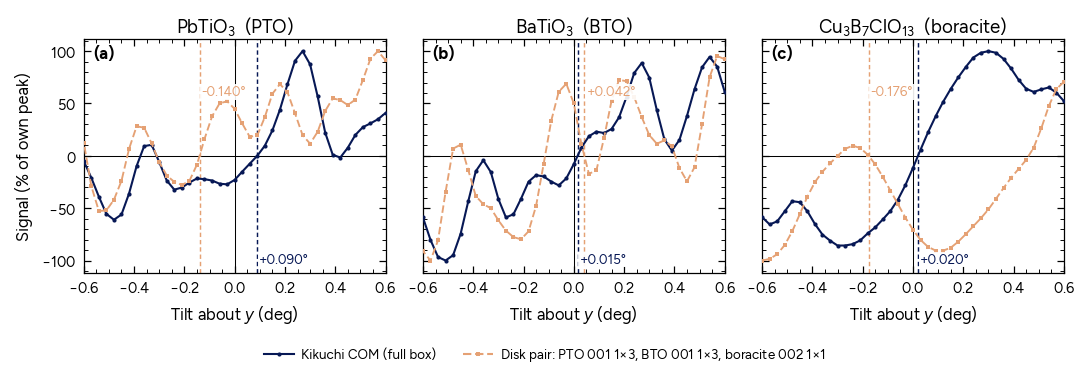

In [4]:
def normalised_figure(mode="paper"):
    """Shared % axis. mode: "paper", "raw" ('unflipped_' prefix) or "aligned" ('aligned_' prefix)."""
    results, pre = RESULTS[mode], {"paper": "", "raw": "unflipped_", "aligned": "aligned_",
                              "final": "corrected_final/corrected_final_"}[mode]
    fig, axes = plt.subplots(1, 3, figsize=(180*MM, 58*MM), layout="constrained")
    fig.get_layout_engine().set(h_pad=0.01, w_pad=0.01, wspace=0.03)
    letters = iter("abc")

    for col, (name, cfg) in enumerate(MATERIALS.items()):
        r = results[name]
        ax = axes[col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        k_peak = np.abs(in_range(r["t_kik"], r["kik"], t_lim)).max()
        ax.plot(r["t_kik"], r["kik"] / k_peak * 100, "-o", ms=2.0, color=C_KIK,
                markeredgewidth=0, zorder=3)
        ax.plot(r["t_disk"], r["disk"] / np.abs(r["disk"]).max() * 100, marker="s", ms=1.8, lw=0.9,
                ls=(0, (4, 1.8)), color=C_DISK, markeredgewidth=0, zorder=3)
        ax.set_xlim(-t_lim, t_lim); ax.set_ylim(-112, 112)
        mark_crossings(ax, r)
        ax.set_xlabel(r"Tilt about $y$ (deg)")
        if col == 0:
            ax.set_ylabel("Signal (% of own peak)")
        else:
            ax.set_yticklabels([])
        ax.set_title(rf"{cfg['formula']}  ({cfg['abbr']})", pad=3, fontsize=9)
        panel_label(ax, next(letters))

    fig.legend(handles, labels, ncol=2, loc="outside lower center",
               handlelength=2.2, columnspacing=2.0, borderaxespad=0.1)

    fig.savefig(f"figures/{pre}combined_disk_kikuchi_normalised.pdf")
    fig.savefig(f"figures/{pre}combined_disk_kikuchi_normalised.png")
    print(f"saved figures/{pre}combined_disk_kikuchi_normalised.{{pdf,png}}")
    plt.show()


normalised_figure()

## Unflipped versions

Raw values as simulated: no `flip_polar` alignment for any material, and `TILT_SIGN` = +1
(tilt axis not mirrored). Saved with the `unflipped_` prefix.

saved figures/unflipped_combined_disk_kikuchi.{pdf,png}


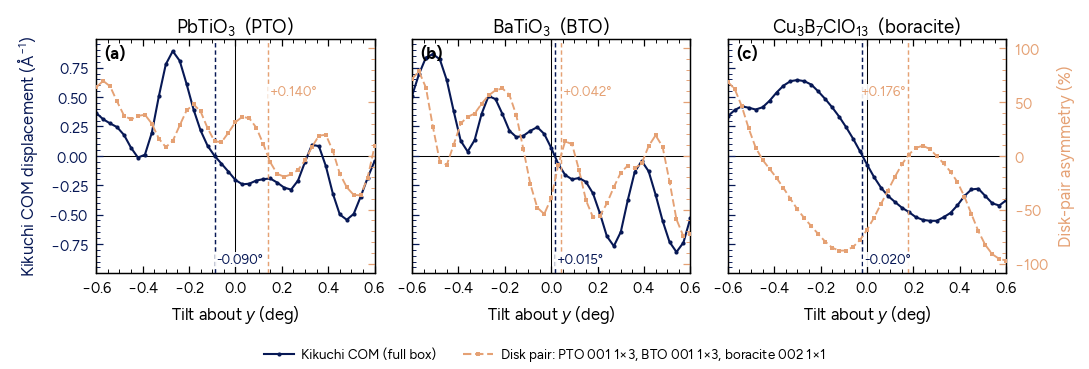

saved figures/unflipped_combined_disk_kikuchi_normalised.{pdf,png}


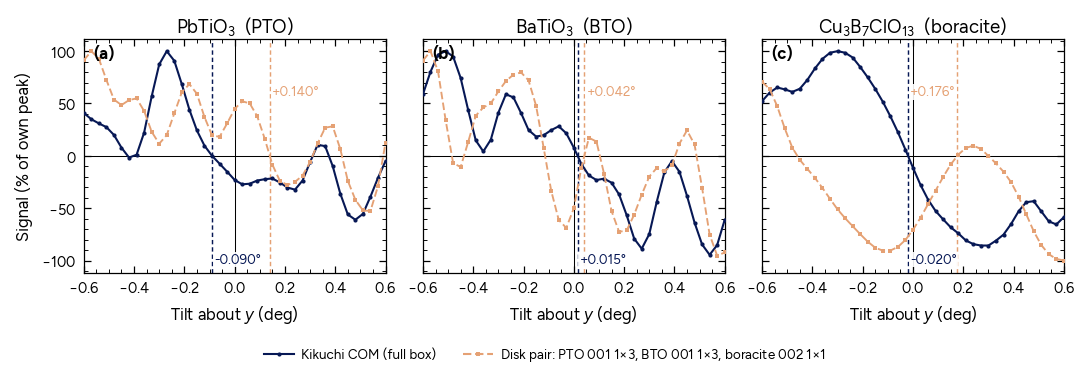

In [5]:
combined_figure("raw")
normalised_figure("raw")

## Correctly oriented versions

What the sims would give had every structure been polarised the same way along the measured
axis (as PTO, +x). From `polarisation_direction.py`: BTO and boracite were simulated with P
reversed relative to PTO (lab P_x = +38.2, -17.9, -0.71 uC/cm2), so both are mirrored,
y(t) -> -y(-t), for both methods; PTO is unchanged. Tilt axis uses `TILT_SIGN` as in the main
figures. Saved with the `aligned_` prefix.

saved figures/aligned_combined_disk_kikuchi.{pdf,png}


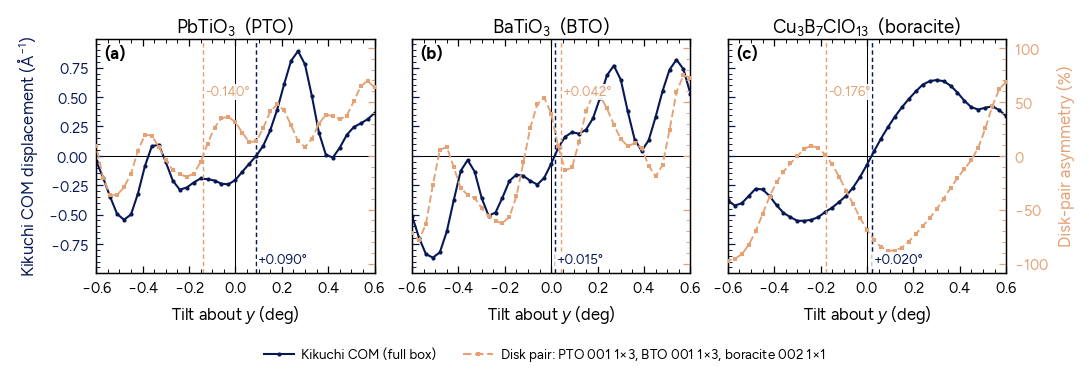

saved figures/aligned_combined_disk_kikuchi_normalised.{pdf,png}


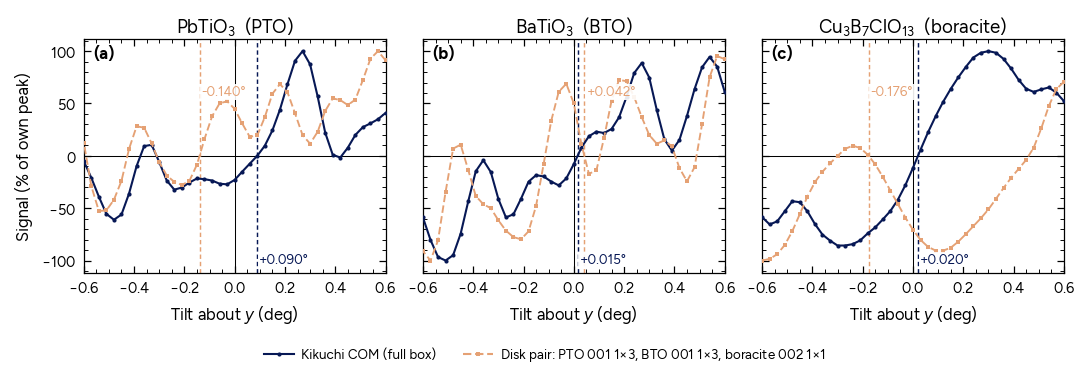

In [6]:
combined_figure("aligned")
normalised_figure("aligned")

saved figures/corrected_final/corrected_final_combined_disk_kikuchi.{pdf,png}


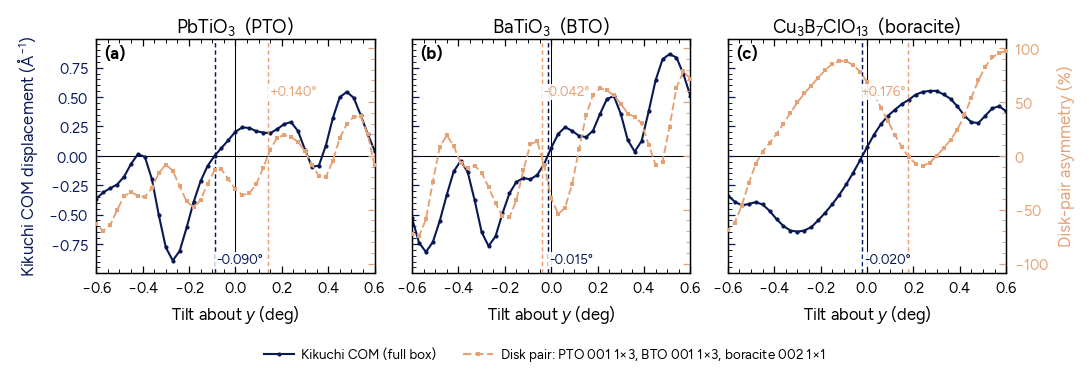

saved figures/corrected_final/corrected_final_combined_disk_kikuchi_normalised.{pdf,png}


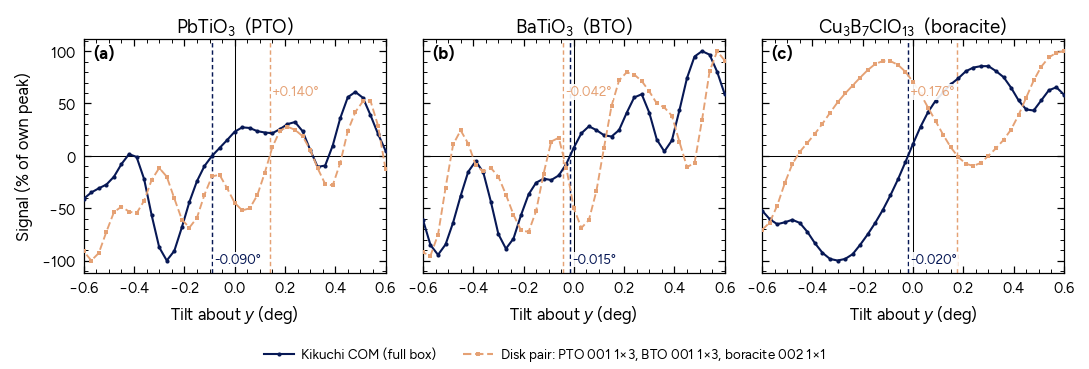

In [7]:
combined_figure("final")
normalised_figure("final")